# Classification and model improvement: Wisconsin breast cancer diagnostic dataset

This notebook documents the workflow, develops and evaluates models distinguishing benign from malignant diagnoses.

In [1]:
# Importing libraries

# Data management
import pandas as pd
import numpy as np

# Visualisations
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning algorithms (splitting, preprocessing, models, cross-validation and metrics)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, 
                             ConfusionMatrixDisplay, RocCurveDisplay)
RANDOM_STATE = 42

print("Libraries imported successfully")

Libraries imported successfully


## Loading and inspecting the dataset
The first checks establish the number of rows and columns, field types, sample records and target labels. The 'Id' and 'Unnamed:32' column should not be used as features because they are not meaningful in this analysis.

In [2]:
# Loading the dataset
df = pd.read_csv("C:\\Users\\charl\\CrossDevice\\Thato's Tab S9 FE (1)\\storage\\Download\\data.csv")
print("Shape:", df.shape)
display(df.head())
print("\nData types:")
print(df.dtypes)
print("\nDiagnosis counts:")
print(df["diagnosis"].value_counts())

Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Data types:
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavi

## Data quality checks and cleaning
Before modelling, the data must be checked for missing values and duplicate values. The extra 'Unnamed:32' column is an empty export artefact, and 'Id' identifies records but does not describe tumour characteristics. Diagnosis is encoded as 0 for benign and 1 for malignant, making the positive class explicit for recall and precision calculations.

In [3]:
print("Missing values per column:")
print(df.isna().sum().sort_values(ascending=False).head(5))
print("Duplicate rows:", df.duplicated().sum())

data = df.drop(columns=["Unnamed: 32"], errors="ignore").drop_duplicates().copy()
data["diagnosis"] = data["diagnosis"].map({"B": 0, "M": 1})
data = data.drop(columns=["id"], errors="ignore")
print("Cleaned shape:", data.shape)
print("Missing values after cleaning:", data.isna().sum().sum())
print("Target counts (0=benign, 1=malignant):\n", data["diagnosis"].value_counts())

Missing values per column:
Unnamed: 32                569
compactness_se               0
fractal_dimension_worst      0
symmetry_worst               0
concave points_worst         0
dtype: int64
Duplicate rows: 0
Cleaned shape: (569, 31)
Missing values after cleaning: 0
Target counts (0=benign, 1=malignant):
 diagnosis
0    357
1    212
Name: count, dtype: int64


## Exploratory data analysis (EDA)
EDA checks class balance and investigates whether selected measurements differ across diagnoses. These plots describe associations, not causal relationships. The feature measurements are on different scales, which is one reason scaling is used within the modelling pipeline. 

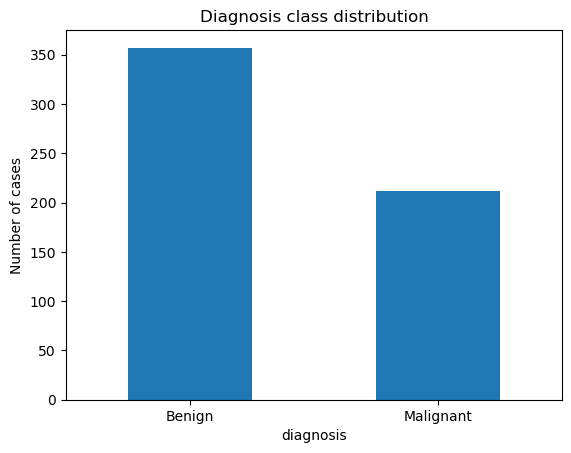

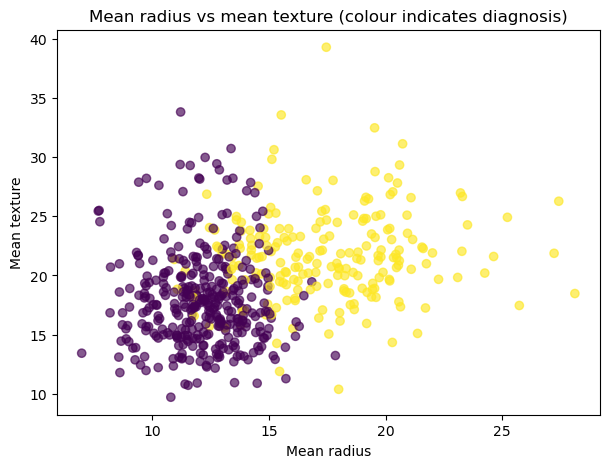

concave points_worst    0.793566
perimeter_worst         0.782914
concave points_mean     0.776614
radius_worst            0.776454
perimeter_mean          0.742636
area_worst              0.733825
radius_mean             0.730029
area_mean               0.708984
concavity_mean          0.696360
concavity_worst         0.659610
compactness_mean        0.596534
compactness_worst       0.590998
Name: diagnosis, dtype: float64


In [4]:
labels = data["diagnosis"].map({0: "Benign", 1: "Malignant"})
labels.value_counts().reindex(["Benign", "Malignant"]).plot(kind="bar")
plt.title("Diagnosis class distribution"); plt.ylabel("Number of cases"); plt.xticks(rotation=0); plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(data["radius_mean"], data["texture_mean"], c=data["diagnosis"], alpha=.65)
plt.xlabel("Mean radius"); plt.ylabel("Mean texture"); plt.title("Mean radius vs mean texture (colour indicates diagnosis)"); plt.show()

# Rank numerica features by absolute correlation with the binary outcome.
correlations = data.corr(numeric_only=True)["diagnosis"].drop("diagnosis")
print(correlations.reindex(correlations.abs().sort_values(ascending=False).index).head(12))


## Defining predictors and splitting the data

The target is separated from the predictors. A stratified 80/20 split preserves approximately the same class prorpotions in training and test sets. The test set is not used to choose hyperparameters.

In [7]:
X = data.drop(columns="diagnosis")
y = data["diagnosis"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print("Training rows:", len(X_train), " Test rows:", len(X_test))
print("Training class proportions:\n", y_train.value_counts(normalize=True))
print("Test class proportions:\n", y_test.value_counts(normalize=True))


Training rows: 455  Test rows: 114
Training class proportions:
 diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64
Test class proportions:
 diagnosis
0    0.631579
1    0.368421
Name: proportion, dtype: float64


## Model choice and training: Logistic regression

Logistic regression is a defensible baseline because the outcome is binary, it produces class probabilities, and its fitted coefficients can be inspected. Standardisation is important because the 30 measurements have different units and ranges. Scaling is placed inside a pipeline so it is fitted only on training folds avoiding leakage. The default 0.5 probability threshold is used for the initial evaluation.

In [9]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))])

logistic_model.fit(X_train, y_train)
y_pred = logistic_model.predict(X_test)
y_prob = logistic_model.predict_proba(X_test)[:, 1]
print("Model trained successfully")

Model trained successfully


## Evaluating the baseline model
Accuracy summarises overall correctness but can hide errors in the less common class. Precision measures how many predicted malignant cases are truly malignant; recall measures how many malignant cases were detected. F1 balances precision and recall. ROC-AUC assesses ranking across thresholds. In a screening-oriented context, false negatives are particularly important, so recall must be considered alongside specificity and precision.

                     Accuracy  Precision  Recall     F1  ROC-AUC
Model                                                           
Logistic regression     0.965      0.975   0.929  0.951    0.996

Classifier report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



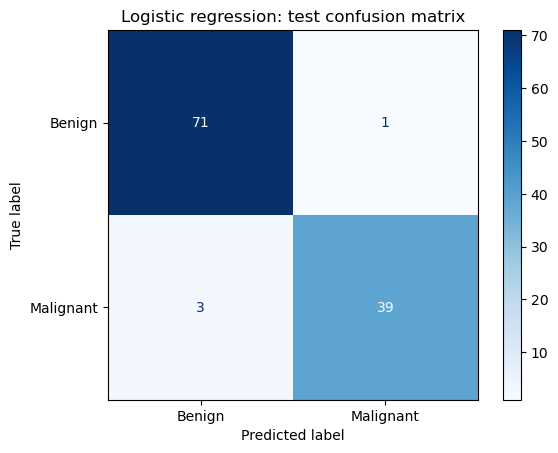

In [13]:
def evaluate_classifier(name, y_true, y_hat, y_score):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_hat),
        "Precision": precision_score(y_true, y_hat),
        "Recall": recall_score(y_true, y_hat),
        "F1": f1_score(y_true, y_hat),
        "ROC-AUC": roc_auc_score(y_true, y_score),}
    return results

baseline_results = evaluate_classifier("Logistic regression", y_test, y_pred, y_prob)
print(pd.DataFrame([baseline_results]).set_index("Model").round(3))
print("\nClassifier report:")
print(classification_report(y_test, y_pred, target_names=["Benign", "Malignant"]))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benign", "Malignant"], cmap="Blues")
plt.title("Logistic regression: test confusion matrix"); plt.show()


## Cross-validation
A five-fold stratified cross-validation is run on the training partition. This gives a less split-dependent estimate of model performance while keeping the held-out test set untouched.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_validate(
    logistic_model, X_train, y_train, cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

cv_summary = pd.DataFrame({
    metric: [cv_scores["test_" + metric].mean(), cv_scores["test_" + metric].std()]
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]}, index=["Mean", "Standard deviation"]).T
display(cv_summary.round(3))

,Mean,Standard deviation
accuracy,0.974,0.015
precision,0.977,0.028
recall,0.953,0.040
f1,0.964,0.021
roc_auc,0.996,0.005


## Improving and comparing with a tuned Support-Vector Classifier

A support vector can model non-linear decision boundaries. The pipeline scales features, and grid search tests a small, declared set of C and kernel values using training-fold ROC-AUC. The test set is used only once for the final comparison. This is a comparison, not proof that one algorithm is universally best.

In [18]:
svc_pipeline = Pipeline([("scaler", StandardScaler()), ("classifier", SVC(probability=True, random_state=RANDOM_STATE))])
param_grid = {"classifier__C": [0.1, 1, 10], "classifier__kernel": ["linear", "rbf"]}
grid = GridSearchCV(svc_pipeline, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train, y_train)
best_svc = grid.best_estimator_
svc_pred = best_svc.predict(X_test)
svc_prob = best_svc.predict_proba(X_test)[:, 1]
print("Best parameters:", grid.best_params_)
comparison = pd.DataFrame([
    evaluate_classifier("Logistic regression", y_test, y_pred, y_prob),
    evaluate_classifier("Tuned SVC", y_test, svc_pred, svc_prob)]).set_index("Model")
display(comparison.round(3))                                                                        

Best parameters: {'classifier__C': 1, 'classifier__kernel': 'rbf'}


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic regression,0.965,0.975,0.929,0.951,0.996
Tuned SVC,0.974,1.000,0.929,0.963,0.995


## ROC curves

ROC curves show the trade-off between the true-positive rate and false-positive rate as the threshold changes. A higher AUC indicates stronger ranking ability, but operational threshold nust be chosen based on the relative consequences of false negatives and false positives, not AUC alone.

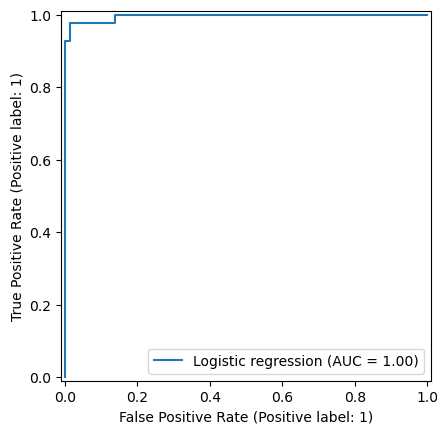

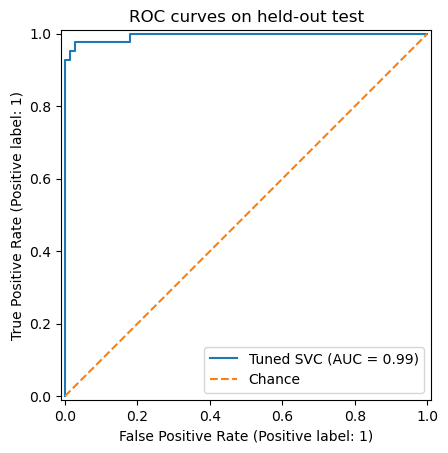

In [20]:
RocCurveDisplay.from_predictions(y_test, y_prob, name="Logistic regression")
RocCurveDisplay.from_predictions(y_test, svc_prob, name="Tuned SVC")
plt.plot([0, 1], [0, 1], "--", label="Chance")
plt.title("ROC curves on held-out test"); plt.legend(); plt.show()